# v.0 Library Usability 

## Preprocessing: from event logs to session sequences

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import sys
import time
from pathlib import Path

# Add v0.2/ root to sys.path so `journey_analyzer` imports cleanly from notebooks/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Top-level API import (tests journey_analyzer/__init__.py)
from journey_analyzer import BaselineAligner

# Sub-package pure function imports (tests journey_analyzer/alignment/__init__.py)
from journey_analyzer.alignment import (
    assign_stages,
    levenshtein_distance,
    normalized_levenshtein_distance,
    weighted_levenshtein_distance,
)

print("Successfully imported BaselineAligner and distance functions!")

Successfully imported BaselineAligner and distance functions!


In [ ]:
df = pd.read_csv('../../data/ecommerce_clickstream_transactions.csv')
print(df.shape)
df.head()

(74817, 7)


,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-07-07 18:00:26.959902,page_view,NaN,NaN,NaN
1,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN
2,1,1,2024-03-23 22:08:10.568453,product_view,prod_8199,NaN,NaN
3,1,1,2024-03-12 00:32:05.495638,add_to_cart,prod_4112,NaN,NaN
4,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN


### Clean and sort

In [ ]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["UserID", "Timestamp", "EventType"]).drop_duplicates()
df["EventType"] = df["EventType"].str.strip().str.lower()
df = df.sort_values(["UserID", "SessionID", "Timestamp"]).reset_index(drop=True)
df["EventType"].value_counts()

EventType
page_view       10819
add_to_cart     10735
product_view    10696
logout          10685
purchase        10682
click           10632
login           10568
Name: count, dtype: int64

In [ ]:
df.head()

,UserID,SessionID,Timestamp,EventType,ProductID,Amount,Outcome
0,1,1,2024-01-01 23:09:51.956825,page_view,NaN,NaN,NaN
1,1,1,2024-02-01 05:13:26.944169,add_to_cart,prod_4965,NaN,NaN
2,1,1,2024-02-14 15:41:53.071258,login,NaN,NaN,NaN
3,1,1,2024-02-25 22:43:01.318876,add_to_cart,prod_3354,NaN,NaN
4,1,1,2024-03-05 22:01:00.072000,page_view,NaN,NaN,NaN


In [ ]:
g = df.groupby(["UserID", "SessionID"])["Timestamp"]
span_h = (g.max() - g.min()).dt.total_seconds() / 3600
gaps_min = g.diff().dt.total_seconds() / 60
print(f"Median session span: {span_h.median():.2f} hours | Max session span: {span_h.max():.2f} hours")
print(f"Gaps longer than 30 minutes: {(gaps_min > 30).mean() * 100:.2f}%")

Median session span: 3847.17 hours | Max session span: 4920.10 hours
Gaps longer than 30 minutes: 86.55%


#### Define sessions

Choose one. `SESSION_MODE = 'session_id'` uses the given IDs; `'inactivity'` starts a new session after 30 min of silence per user.

In [ ]:
SESSION_MODE = "session_id"   # or "inactivity"
GAP_MIN = 30

if SESSION_MODE == "session_id":
    df["session_key"] = df.groupby(["UserID", "SessionID"]).ngroup()
else:
    df = df.sort_values(["UserID", "Timestamp"])
    new = df.groupby("UserID")["Timestamp"].diff().gt(pd.Timedelta(minutes=GAP_MIN))
    new |= df["UserID"].ne(df["UserID"].shift())
    df["session_key"] = new.cumsum()

#### Build sequences and filter by length

In [ ]:
df = df.sort_values(["session_key", "Timestamp"])
sessions = (df.groupby("session_key")
              .agg(user=("UserID", "first"),
                   events=("EventType", list),
                   outcome=("Outcome", lambda s: s.dropna().iloc[-1] if s.notna().any() else None),
                   total_amount=("Amount", "sum")))
sessions["n_events"] = sessions["events"].str.len()

hi = np.percentile(sessions["n_events"], 99)
sessions = sessions[(sessions["n_events"] >= 2) & (sessions["n_events"] <= hi)]

sequences = sessions["events"].tolist()   # list[list[str]] -> input for Levenshtein
print(len(sequences), "sessions")
sessions.head()

10000 sessions


,user,events,outcome,total_amount,n_events
session_key,,,,,
0,1,"[page_view, add_to_cart, login, add_to_cart, p...",None,0.000000,9
1,1,"[page_view, page_view, logout, product_view, c...",None,0.000000,6
2,1,"[page_view, login, add_to_cart, click, add_to_...",purchase,72.913619,9
3,1,"[add_to_cart, add_to_cart, login, page_view, a...",purchase,7.677938,10
4,1,"[logout, purchase, purchase, product_view, log...",purchase,998.570616,9


### 1. Pairwise Distance Functions (`distance.py`)
Test the three stateless metrics (`levenshtein`, `normalized`, and `weighted`) on individual preprocessed sessions before building full matrices.

In [ ]:
seq_no_buy_1 = sessions["events"][0]  # 9 events, outcome: None
seq_no_buy_2 = sequences[1]  # 6 events, outcome: None
seq_purchase = sequences[2]  # 9 events, outcome: purchase

print("s0 (no purchase):", seq_no_buy_1)
print("s1 (no purchase):", seq_no_buy_2)
print("s2 (purchase)   :", seq_purchase)

# 1. Classic & Normalized Levenshtein
print("\n--- Classic vs. Normalized Levenshtein ---")
print(f"s0 vs s1 -> raw: {levenshtein_distance(seq_no_buy_1, seq_no_buy_2):.1f} | "
      f"norm: {normalized_levenshtein_distance(seq_no_buy_1, seq_no_buy_2):.3f}")
print(f"s0 vs s2 -> raw: {levenshtein_distance(seq_no_buy_1, seq_purchase):.1f} | "
      f"norm: {normalized_levenshtein_distance(seq_no_buy_1, seq_purchase):.3f}")

# 2. Funnel Stage Mapping for the 7 dataset EventTypes
EVENT_TO_STAGE = {
    "login":        "pre",
    "page_view":    "browse",
    "product_view": "browse",
    "click":        "browse",
    "add_to_cart":  "intent",
    "purchase":     "conversion",
    "logout":       "post",
}

STAGE_WEIGHTS = {
    "pre":        0.5,
    "browse":     1.0,
    "intent":     2.0,
    "conversion": 3.0,
    "post":       0.5,
}

staged_s0 = assign_stages(seq_no_buy_1, EVENT_TO_STAGE)
staged_s2 = assign_stages(seq_purchase, EVENT_TO_STAGE)

print("\n--- Stage-Aware Weighted Levenshtein (Buy (s2) vs No Buy (s0) ---")
print("Staged s2 (first 4):", staged_s2[:4])
print(f"Unweighted stage distance (all weights=1.0): {weighted_levenshtein_distance(staged_s0, staged_s2):.2f}")
print(f"Weighted stage distance (conversion=3.0)   : {weighted_levenshtein_distance(staged_s0, staged_s2, STAGE_WEIGHTS):.2f}")
print("We can see how weighted distance is going to distance more the actual purchase journeys than the ones that do not")

s0 (no purchase): ['page_view', 'add_to_cart', 'login', 'add_to_cart', 'page_view', 'add_to_cart', 'product_view', 'click', 'page_view']
s1 (no purchase): ['page_view', 'page_view', 'logout', 'product_view', 'click', 'page_view']
s2 (purchase)   : ['page_view', 'login', 'add_to_cart', 'click', 'add_to_cart', 'login', 'purchase', 'product_view', 'add_to_cart']

--- Classic vs. Normalized Levenshtein ---
s0 vs s1 -> raw: 4.0 | norm: 0.444
s0 vs s2 -> raw: 6.0 | norm: 0.667

--- Stage-Aware Weighted Levenshtein (Buy (s2) vs No Buy (s0) ---
Staged s2 (first 4): [('page_view', 'browse'), ('login', 'pre'), ('add_to_cart', 'intent'), ('click', 'browse')]
Unweighted stage distance (all weights=1.0): 5.00
Weighted stage distance (conversion=3.0)   : 6.50
We can see how weighted distance is going to distance more the actual purchase journeys than the ones that do not


### 2. Pairwise Distance Matrices (`BaselineAligner`)
Build $N \times N$ symmetric distance matrices on a stratified sample of sessions (100 converting vs. 100 non-converting) to compare all three metrics visually.

[levenshtein] 200x200 matrix in 0.305s | mean=6.57, median=7.00, max=10.00
[normalized ] 200x200 matrix in 0.315s | mean=0.77, median=0.78, max=1.00
[weighted   ] 200x200 matrix in 0.228s | mean=9.41, median=9.00, max=28.50


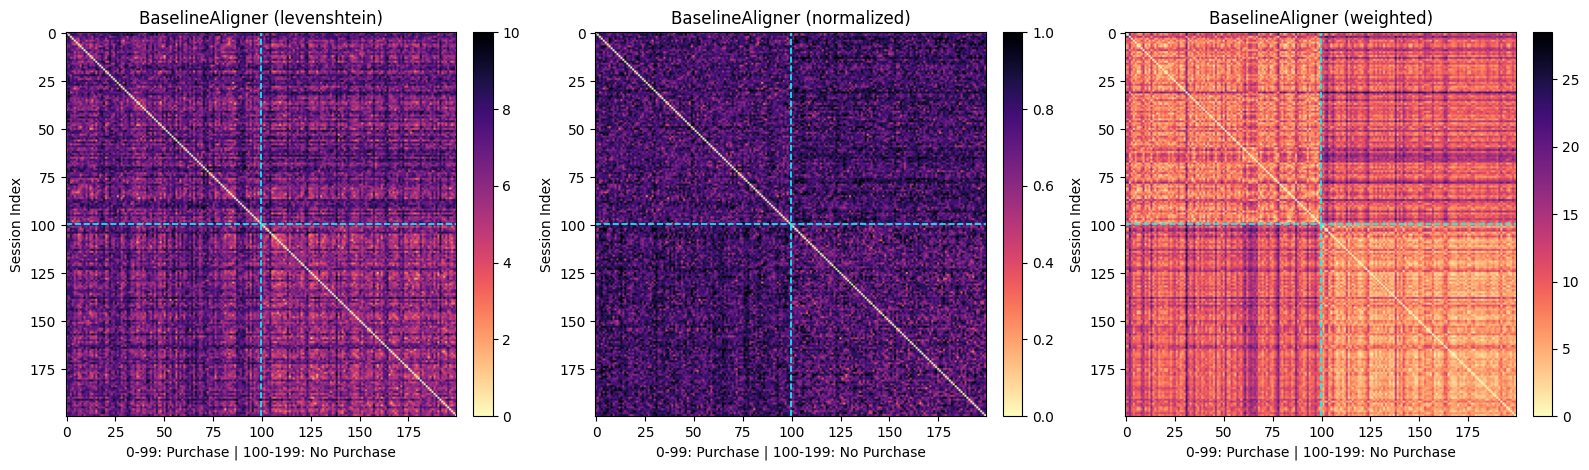

In [ ]:
# Build a balanced sample of 200 sessions: first 100 = purchase, next 100 = no purchase
buy_seqs = sessions[sessions["outcome"] == "purchase"]["events"].iloc[:100].tolist()
nobuy_seqs = sessions[sessions["outcome"].isna()]["events"].iloc[:100].tolist()
sample_sequences = buy_seqs + nobuy_seqs

aligners = {
    "levenshtein": BaselineAligner(metric="levenshtein"),
    "normalized":  BaselineAligner(metric="normalized"),
    "weighted":    BaselineAligner(
        metric="weighted",
        event_to_stage=EVENT_TO_STAGE,
        stage_weights=STAGE_WEIGHTS,
    ),
}

matrices = {}
for name, al in aligners.items():
    t0 = time.perf_counter()
    D = al.fit_distance_matrix(sample_sequences)
    dt = time.perf_counter() - t0
    matrices[name] = D

    # Verify BaselineAligner mathematical & state guarantees
    assert D.shape == (200, 200) and D.dtype == np.float32
    assert np.allclose(np.diag(D), 0.0), "Diagonal must be 0"
    assert np.allclose(D, D.T), "Matrix must be symmetric"
    assert not D.flags.writeable, "Matrix must be read-only"

    print(f"[{name:<11}] 200x200 matrix in {dt:.3f}s | "
          f"mean={D.mean():.2f}, median={np.median(D):.2f}, max={D.max():.2f}")

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, D) in zip(axes, matrices.items()):
    im = ax.imshow(D, cmap="magma_r", aspect="auto")
    ax.axhline(99.5, color="cyan", linestyle="--", linewidth=1.2)
    ax.axvline(99.5, color="cyan", linestyle="--", linewidth=1.2)
    ax.set_title(f"BaselineAligner ({name})")
    ax.set_xlabel("0-99: Purchase | 100-199: No Purchase")
    ax.set_ylabel("Session Index")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()